# NQ_IBB_Development

## 1.1 Systematic Trading Approach following TIS Framework

This notebook builds and validates the **Initial Balance Break Out (IBB)** strategy
on **NQ futures**, adapting the documented blueprint (`Estrategia_3_Nasdaq_IBB.md`,
originally specified for QQQ RTH-only) to the 24h continuous NQ futures session
already characterized in `NQ_EDA.md`.

**Phase**: Research / Strategy Development (post-EDA). This notebook does **not**
re-derive dataset-level facts already locked in the NQ EDA (gap structure, data
completeness, liquidity profile) -- it consumes them as inputs and documents the
instrument-specific adaptation decisions required to port the QQQ blueprint to NQ.

We will:
- Load `nq_15min` from MongoDB (same source as the EDA).
- Reconstruct the Initial Balance (09:30-10:30 NY) and IB% volatility filter.
- Implement entry/exit logic exactly as specified (Wick/Close trigger, TP/SL as
  IB-Range multiples, forced close) with the **futures-specific** adaptations
  called out explicitly below.
- Run the base-case backtest and reproduce the strategy doc's validation table
  format (win rate, payoff ratio, profit factor, total return, max drawdown,
  expectancy/trade) on NQ data.
- Flag any structural differences vs. the original QQQ statistics as open
  questions for the robustness notebook, not resolve them here.



## 1.2 Documented Adaptations: QQQ Blueprint -> NQ Futures

These are the **only** deviations from `Estrategia_3_Nasdaq_IBB.md` made in this
notebook. Every other parameter (IB window, IB% >= 0.55%, TP = entry + 0.60xIBRange,
SL = entry - 0.40xIBRange clipped at IB Low/High, entry window 10:30-13:30 NY,
1 trade/session) is carried over unchanged.


All strategy logic lives in `ibb_engine.py` (shared with the robustness
notebook) so both notebooks test the *exact same* implementation.


In [1]:

import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

utils_path = os.path.abspath('../../utils')
if utils_path not in sys.path:
    sys.path.insert(0, utils_path)
from utils import load_data_from_mongo, to_session_date

# ibb_engine.py ships alongside this notebook (same directory)
sys.path.insert(0, os.path.abspath('.'))
from ibb_engine import IBBConfig, run_backtest, compute_metrics, print_metrics_table

print("Imports and configuration complete.")
print(f"Loaded utils from: {utils_path}")


Imports and configuration complete.
Loaded utils from: /Users/luyandy/Documents/AlphaCapital/AlphaCapital-Research/research_development/utils


## 1.3 Load Data From MongoDB

In [2]:

df_raw = load_data_from_mongo('nq_15min')
print(f"Raw data shape: {df_raw.shape}")
print(f"Date range: {df_raw.index.min()} \u2192 {df_raw.index.max()}")
df_raw.head()


Raw data shape: (397830, 5)
Date range: 2009-09-27 18:00:00 → 2026-08-28 16:45:00


,open,high,low,close,volume
time,,,,,
2009-09-27 18:00:00,1697.00,1701.00,1696.00,1699.25,596
2009-09-27 18:15:00,1699.25,1700.00,1699.25,1699.50,25
2009-09-27 18:30:00,1699.75,1700.00,1699.50,1699.50,15
2009-09-27 18:45:00,1699.50,1699.50,1699.25,1699.50,11
2009-09-27 19:00:00,1699.50,1699.75,1694.00,1696.00,584



## 1.4 Session Tagging

Each 15-min bar is tagged with its **session_date** using the same
`to_session_date` convention as the EDA (session opens 18:00 NY, rolls into
the next calendar day). The Initial Balance for a given session is built from
the bars at 09:30/09:45/10:00/10:15 NY that fall *inside* that session.


In [3]:

df_raw = df_raw.copy()
df_raw['session_date'] = [to_session_date(ts) for ts in df_raw.index]

n_sessions = df_raw['session_date'].nunique()
print(f"Sessions available: {n_sessions}")
print(f"First session: {df_raw['session_date'].min()}  |  Last session: {df_raw['session_date'].max()}")


Sessions available: 4386
First session: 2009-09-28  |  Last session: 2026-08-28



## 2.1 Base-Case Backtest (Blueprint Defaults, NQ-Adapted)

Config below mirrors the blueprint 1-to-1, with only the documented
adaptations from section 1.2 applied (`forced_close_time`, `point_value`).
No parameter search happens in this notebook -- that belongs to the
robustness notebook.


In [4]:

cfg = IBBConfig(
    ib_start="09:30",
    ib_end_exclusive="10:30",
    entry_window_start="10:30",
    entry_window_end="13:30",
    forced_close_time="15:30",     # <-- CAMBIO 1: volver a la sesión RTH, no 23:00
    ib_pct_min=0.75,                # <-- CAMBIO 2: recalibrado a la mediana/p75 real de NQ (era 0.55, heredado sin ajustar)
    ib_pct_extreme=2.00,
    tp_mult=0.60,
    sl_mult=0.40,
    entry_mode="close",             # <-- CAMBIO 3: confirmado en cierre, coherente con granularidad de 15min
    max_trades_per_session=1,
    point_value=20.0,
    contracts=1,
    slippage_points=1.00,
    commission_points=0.30,
)

trades_df = run_backtest(df_raw, cfg)
print(f"Sessions evaluated: {len(trades_df)}")
trades_df.head(10)


Sessions evaluated: 4361


,session_date,ib_high,ib_low,ib_mid,ib_range,ib_pct,traded,direction,entry_time,entry_price,exit_time,exit_price,exit_reason,pnl_points,pnl_pct,pnl_usd,no_trade_reason
0,2009-09-27,1724.25,1700.75,1712.500,23.50,1.372263,True,long,2009-09-28 10:30:00,1725.25,2009-09-28 15:30:00,1722.00,TIME,-3.55,-0.205767,-71.0,NaN
1,2009-09-28,1730.75,1711.00,1720.875,19.75,1.147672,True,short,2009-09-29 11:45:00,1710.00,2009-09-29 12:45:00,1718.90,SL,-9.20,-0.538012,-184.0,NaN
2,2009-09-29,1725.50,1688.75,1707.125,36.75,2.152742,False,NaN,NaT,NaN,NaT,NaN,NaN,NaN,NaN,NaN,no_breakout_in_window
3,2009-09-30,1711.00,1685.25,1698.125,25.75,1.516378,True,short,2009-10-01 11:00:00,1684.25,2009-10-01 13:15:00,1669.80,TP,14.15,0.840137,283.0,NaN
4,2009-10-01,1673.00,1652.75,1662.875,20.25,1.217770,False,NaN,NaT,NaN,NaT,NaN,NaN,NaN,NaN,NaN,no_breakout_in_window
5,2009-10-04,1674.00,1658.00,1666.000,16.00,0.960384,True,long,2009-10-05 10:30:00,1675.00,2009-10-05 10:30:00,1667.60,SL,-7.70,-0.459701,-154.0,NaN
6,2009-10-05,1706.25,1681.75,1694.000,24.50,1.446281,True,long,2009-10-06 11:00:00,1707.25,2009-10-06 13:45:00,1696.45,SL,-11.10,-0.650168,-222.0,NaN
7,2009-10-06,1708.75,1696.25,1702.500,12.50,0.734214,False,NaN,NaT,NaN,NaT,NaN,NaN,NaN,NaN,NaN,ib_pct_below_min
8,2009-10-07,1724.25,1711.25,1717.750,13.00,0.756804,True,long,2009-10-08 11:15:00,1725.25,2009-10-08 11:15:00,1719.05,SL,-6.50,-0.376757,-130.0,NaN
9,2009-10-08,1725.00,1707.75,1716.375,17.25,1.005025,False,NaN,NaT,NaN,NaT,NaN,NaN,NaN,NaN,NaN,no_breakout_in_window


### 2.2 Base-Case Performance (frictionless)

In [5]:

metrics_base = compute_metrics(trades_df)
print_metrics_table(metrics_base, label="NQ IBB -- Base Case (no costs)")


IBB METRICS -- NQ IBB -- Base Case (no costs)
total_sessions          : 4361
total_trades            : 1399
trade_frequency_pct     : 32.080
win_rate_pct            : 52.823
avg_win_pct             : 0.550
avg_loss_pct            : -0.443
payoff_ratio            : 1.243
profit_factor           : 1.611
total_return_pct        : 323.457
max_drawdown_pct        : -5.605
expectancy_usd          : 231.206
avg_hold_minutes        : 121.490
final_equity            : 423,457.000



### 2.3 Cost-Adjusted Performance

Applies a conservative slippage + commission estimate in index points per
round-turn. Values are placeholders -- replace with your broker/prop-firm's
actual NQ commission and a slippage estimate consistent with the EDA's
reopen-liquidity finding (18.1% of rest-of-session average volume; most IBB
entries occur well after reopen, in the 10:30-13:30 NY window, where
liquidity is materially higher, but this should still be validated against
your fill data before going live).


In [6]:

cfg_costed = IBBConfig(**{**cfg.__dict__, "slippage_points": 1.00, "commission_points": 0.30})
trades_df_costed = run_backtest(df_raw, cfg_costed)
metrics_costed = compute_metrics(trades_df_costed)
print_metrics_table(metrics_costed, label="NQ IBB -- Cost-Adjusted (1.00pt slip + 0.30pt commission per RT)")

IBB METRICS -- NQ IBB -- Cost-Adjusted (1.00pt slip + 0.30pt commission per RT)
total_sessions          : 4361
total_trades            : 1399
trade_frequency_pct     : 32.080
win_rate_pct            : 52.823
avg_win_pct             : 0.550
avg_loss_pct            : -0.443
payoff_ratio            : 1.243
profit_factor           : 1.611
total_return_pct        : 323.457
max_drawdown_pct        : -5.605
expectancy_usd          : 231.206
avg_hold_minutes        : 121.490
final_equity            : 423,457.000



## 2.4 No-Trade Diagnostics

Breaks down *why* sessions didn't trade -- mirrors the blueprint's "CASO
FILTRADO" example (IB% valid but breakout arrived outside the entry window).
Useful sanity check before trusting the headline stats above.


In [7]:

no_trade = trades_df[~trades_df['traded']]
print("No-trade reason counts:")
print(no_trade['no_trade_reason'].value_counts())
print(f"\nShare of sessions filtered by IB% < {cfg.ib_pct_min}%: "
      f"{(no_trade['no_trade_reason'] == 'ib_pct_below_min').sum() / len(trades_df) * 100:.1f}%")


No-trade reason counts:
no_trade_reason
ib_pct_below_min         2546
no_breakout_in_window     416
Name: count, dtype: int64

Share of sessions filtered by IB% < 0.75%: 58.4%



## 2.5 IB% Distribution vs. Filter Threshold

Confirms the 0.55% filter is calibrated to NQ's own volatility distribution,
not just inherited from QQQ. Compare against the gap-size distributions
already characterized in the ES/NQ EDA notebooks for a cross-instrument sanity
check.


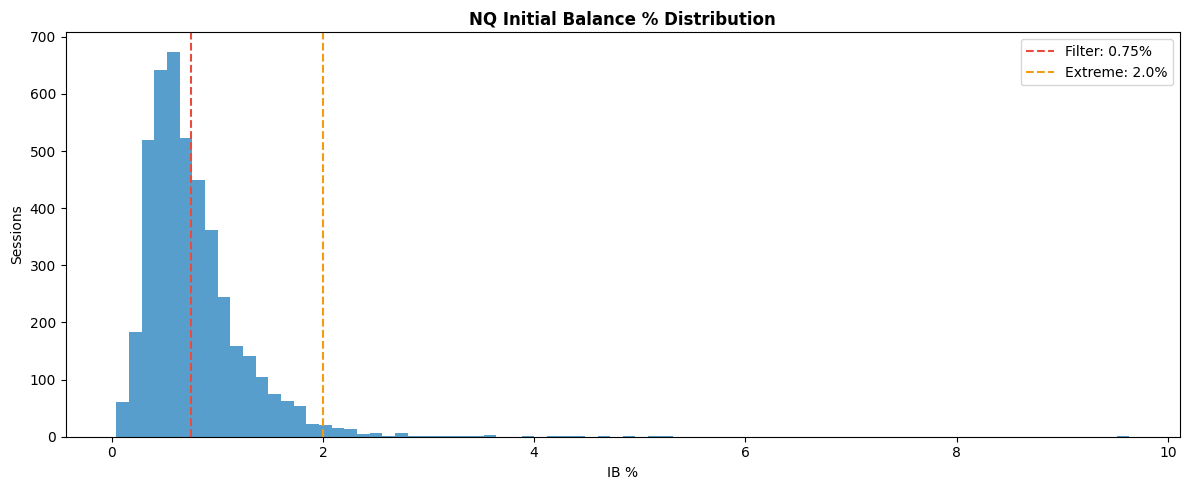

count    4361.000000
mean        0.772108
std         0.483577
min         0.042872
25%         0.464258
50%         0.663564
75%         0.947508
max         9.636078
Name: ib_pct, dtype: float64


In [8]:

fig, ax = plt.subplots(figsize=(12, 5))
ax.hist(trades_df['ib_pct'].dropna(), bins=80, color='#2E86C1', alpha=0.8)
ax.axvline(cfg.ib_pct_min, color='#E74C3C', linestyle='--', label=f'Filter: {cfg.ib_pct_min}%')
ax.axvline(cfg.ib_pct_extreme, color='#F39C12', linestyle='--', label=f'Extreme: {cfg.ib_pct_extreme}%')
ax.set_title('NQ Initial Balance % Distribution', fontweight='bold')
ax.set_xlabel('IB %')
ax.set_ylabel('Sessions')
ax.legend()
plt.tight_layout()
plt.show()

print(trades_df['ib_pct'].describe())



## 2.6 Equity Curve


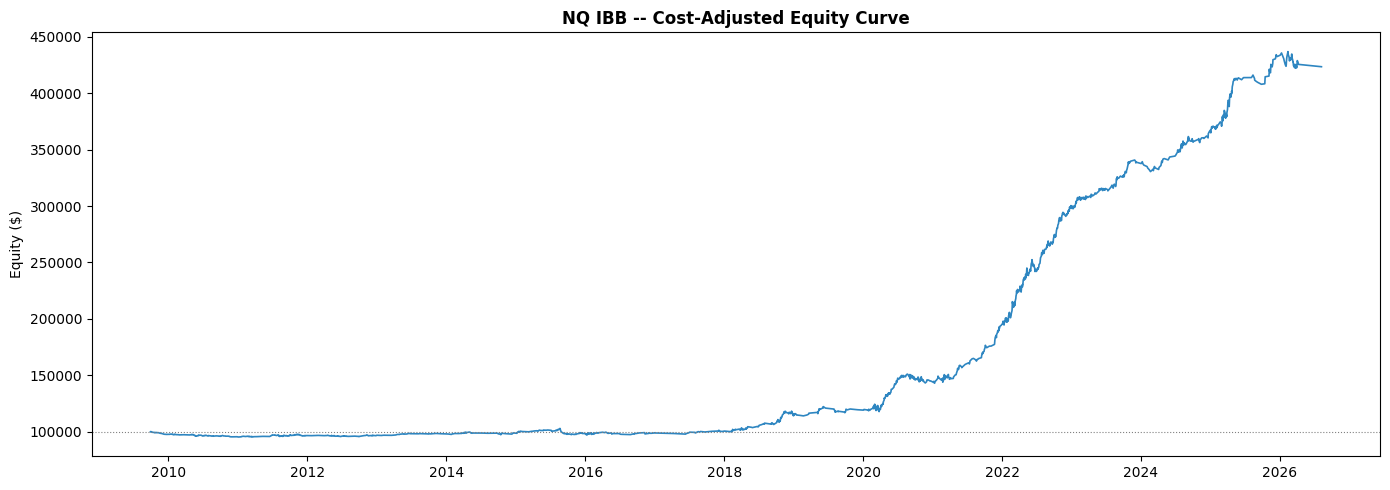

In [9]:
traded = trades_df_costed[trades_df_costed['traded']].copy()
traded = traded.sort_values('entry_time')
equity = 100_000 + traded['pnl_usd'].cumsum()

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(traded['entry_time'], equity, color='#2E86C1', linewidth=1.2)
ax.set_title('NQ IBB -- Cost-Adjusted Equity Curve', fontweight='bold')
ax.set_ylabel('Equity ($)')
ax.axhline(100_000, color='gray', linestyle=':', linewidth=0.8)
plt.tight_layout()
plt.show()


In [10]:
# --- Tradeify-style EOD trailing drawdown simulator ---
# Place this in the Development notebook, right after the cost-adjusted equity curve (cell [9]),
# or as a new section 2.8 "Prop Firm Drawdown Fit" at the end of the notebook.

def simulate_eod_trailing_breach(daily_pnl, starting_balance, max_dd, lock_buffer=100.0):
    """Replays Tradeify's EOD trailing drawdown mechanic on a sequence of daily P&L.
    Floor recalculates only at end-of-day, locks permanently once EOD balance
    reaches starting_balance + max_dd + lock_buffer.
    Returns: dict with breach info and the full floor/balance/buffer series.
    """
    balance = starting_balance
    floor = starting_balance - max_dd
    lock_trigger = starting_balance + max_dd + lock_buffer
    locked = False
    locked_floor = starting_balance + lock_buffer

    balances, floors, buffers = [balance], [floor], [balance - floor]
    breach_day = None

    for i, pnl in enumerate(daily_pnl):
        balance += pnl
        # Enforced in real time against the *current* (pre-update) floor:
        if balance <= floor and breach_day is None:
            breach_day = i
        # EOD recalculation:
        if not locked:
            if balance >= lock_trigger:
                locked = True
                floor = locked_floor
            else:
                floor = max(floor, balance - max_dd)
        balances.append(balance)
        floors.append(floor)
        buffers.append(balance - floor)
        if breach_day is not None:
            break

    return {
        "breached": breach_day is not None,
        "breach_day_index": breach_day,
        "min_buffer_usd": min(buffers),
        "final_balance": balances[-1],
        "balances": balances,
        "floors": floors,
        "buffers": buffers,
    }

# Run against the realistic cost-adjusted historical path (1 contract)
traded_costed = trades_df_costed[trades_df_costed['traded']].sort_values('entry_time')
daily_pnl = traded_costed['pnl_usd'].values  # one entry per traded session, chronological

tradeify_tiers = {
    "50K":  {"starting_balance": 50_000, "max_dd": 2_000},
    "100K": {"starting_balance": 100_000, "max_dd": 3_500},
    "150K": {"starting_balance": 150_000, "max_dd": 5_000},
}

print("=== Tradeify EOD Trailing Drawdown -- Historical Fit (1 contract) ===")
for tier, params in tradeify_tiers.items():
    result = simulate_eod_trailing_breach(daily_pnl, **params)
    status = f"BREACHED at trade #{result['breach_day_index']}" if result['breached'] else "survived full history"
    print(f"{tier}: {status} | worst buffer above floor: ${result['min_buffer_usd']:,.0f}")

=== Tradeify EOD Trailing Drawdown -- Historical Fit (1 contract) ===
50K: BREACHED at trade #25 | worst buffer above floor: $-114
100K: BREACHED at trade #62 | worst buffer above floor: $-290
150K: BREACHED at trade #414 | worst buffer above floor: $-231



## 2.7 Worked Examples (cross-check against blueprint's didactic cases)

Pulls the best trade, worst trade, and a representative filtered ("no
breakout in window" / "IB% below min") session from the actual NQ results,
in the same format as the blueprint's CASO GANADOR / CASO PERDEDOR / CASO
FILTRADO examples, for a qualitative sanity check.


In [11]:

traded_all = trades_df_costed[trades_df_costed['traded']].copy()

if len(traded_all):
    best = traded_all.loc[traded_all['pnl_usd'].idxmax()]
    worst = traded_all.loc[traded_all['pnl_usd'].idxmin()]

    for label, row in [("BEST TRADE", best), ("WORST TRADE", worst)]:
        print(f"--- {label} ---")
        print(f"Session: {row['session_date']}  Direction: {row['direction']}")
        print(f"Entry: {row['entry_time']}  @ {row['entry_price']:.2f}")
        print(f"Exit:  {row['exit_time']}  @ {row['exit_price']:.2f}  ({row['exit_reason']})")
        print(f"IB Range: {row['ib_range']:.2f}  IB%: {row['ib_pct']:.2f}%")
        print(f"PnL: {row['pnl_points']:.2f} pts | {row['pnl_pct']:.2f}% | \${row['pnl_usd']:.2f}")
        print()

filtered_example = trades_df[trades_df['no_trade_reason'] == 'ib_pct_below_min'].head(1)
if len(filtered_example):
    row = filtered_example.iloc[0]
    print("--- FILTERED SESSION EXAMPLE ---")
    print(f"Session: {row['session_date']}  IB%: {row['ib_pct']:.2f}% (< {cfg.ib_pct_min}%)")
    print("Result: SIN OPERAR (filtered by volatility threshold)")


--- BEST TRADE ---
Session: 2022-02-23  Direction: long
Entry: 2022-02-24 11:00:00  @ 13484.25
Exit:  2022-02-24 14:30:00  @ 13738.40  (TP)
IB Range: 425.25  IB%: 3.20%
PnL: 253.85 pts | 1.88% | \$5077.00

--- WORST TRADE ---
Session: 2020-09-03  Direction: short
Entry: 2020-09-04 10:30:00  @ 11352.00
Exit:  2020-09-04 12:30:00  @ 11549.00  (SL)
IB Range: 490.00  IB%: 4.22%
PnL: -197.30 pts | -1.74% | \$-3946.00

--- FILTERED SESSION EXAMPLE ---
Session: 2009-10-06  IB%: 0.73% (< 0.75%)
Result: SIN OPERAR (filtered by volatility threshold)



## 3. Summary & Handoff to Robustness Notebook

Record here (fill in after running against your live MongoDB data):

- Base-case vs. cost-adjusted headline metrics
- Trade frequency vs. project constraint (>= 1 trade/week) -- confirm met
- Any material divergence from the QQQ blueprint's 1yr/5yr statistics, and a
  hypothesis for why (index composition, futures overnight gaps, session
  structure, 15-min vs 5-min trigger resolution)
- Open parameter choices to stress-test: `ib_pct_min`, `tp_mult`/`sl_mult`,
  `point_value`/contract selection (NQ vs MNQ), slippage assumption

This notebook intentionally stops at a single in-sample backtest. Out-of-
sample validation, walk-forward analysis, Monte Carlo simulation, and
parameter sensitivity live in **`NQ_IBB_Robustness.ipynb`**, per the TIS
methodology (Modulo_6_5 / Modulo_7): no strategy is considered validated
until it passes robustness testing on data not used to build it here.
